# 01 - Exploratory analysis and data-integrity audit
Runs from the repository root and only reads files in `outputs/`, `reports/` and `legacy/`
(no dataset needed). Outputs below were produced from those files.

In [1]:
import pandas as pd
from IPython.display import Image, display

split = pd.read_csv('outputs/baseline/split.csv')
split.groupby(['label', 'split']).size().unstack()[['train', 'validation', 'test']]

split         train  validation  test
label                                
Early_blight    700         150   150
Late_blight     700         150   150
healthy         106          23    23

## 1. Class distribution (clean, de-duplicated dataset: 2,152 images)

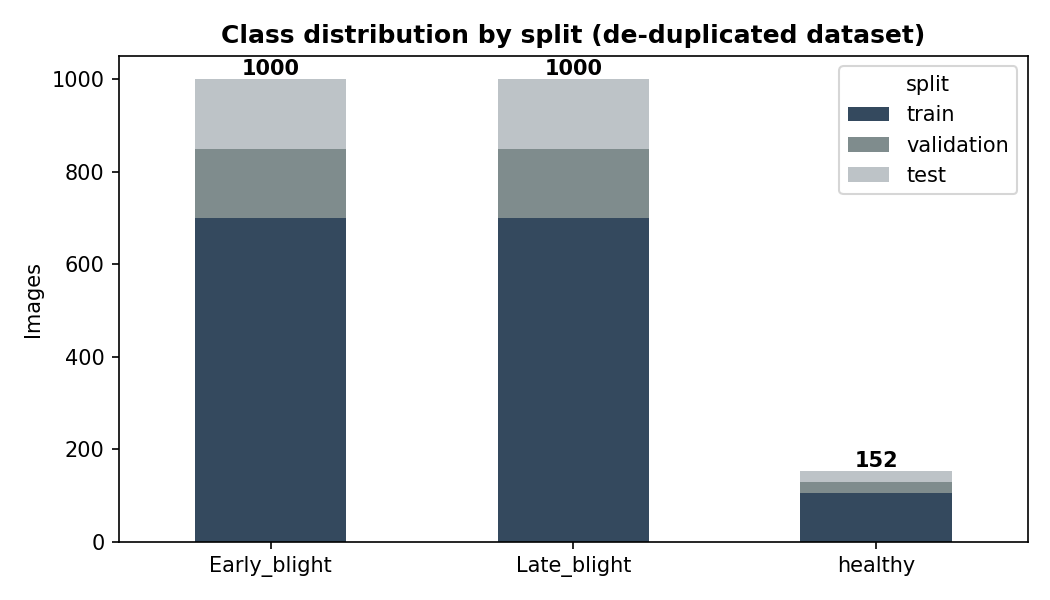

In [2]:
Image('reports/figures/class_distribution.png')

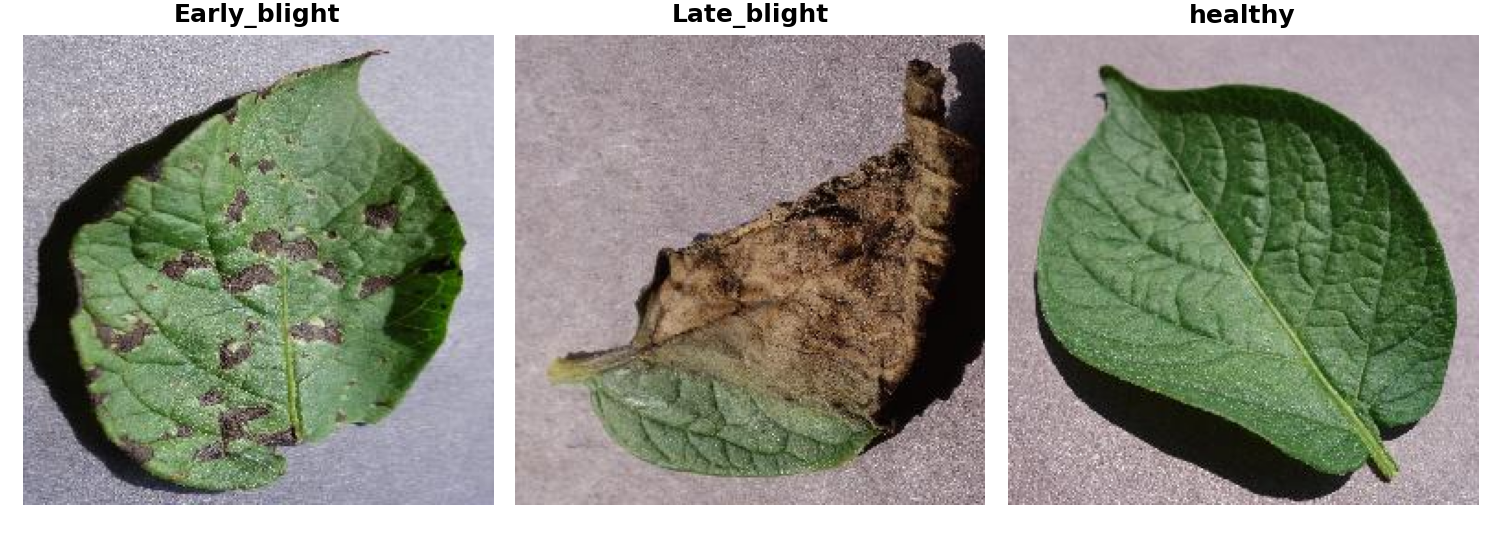

In [3]:
Image('reports/figures/sample_images.png')

## 2. Distribution reported by the original run
The original coursework figure shows **2,000 / 2,000 / 304**, exactly twice the 1,000 / 1,000 / 152 above. This is the first sign of duplicated data.

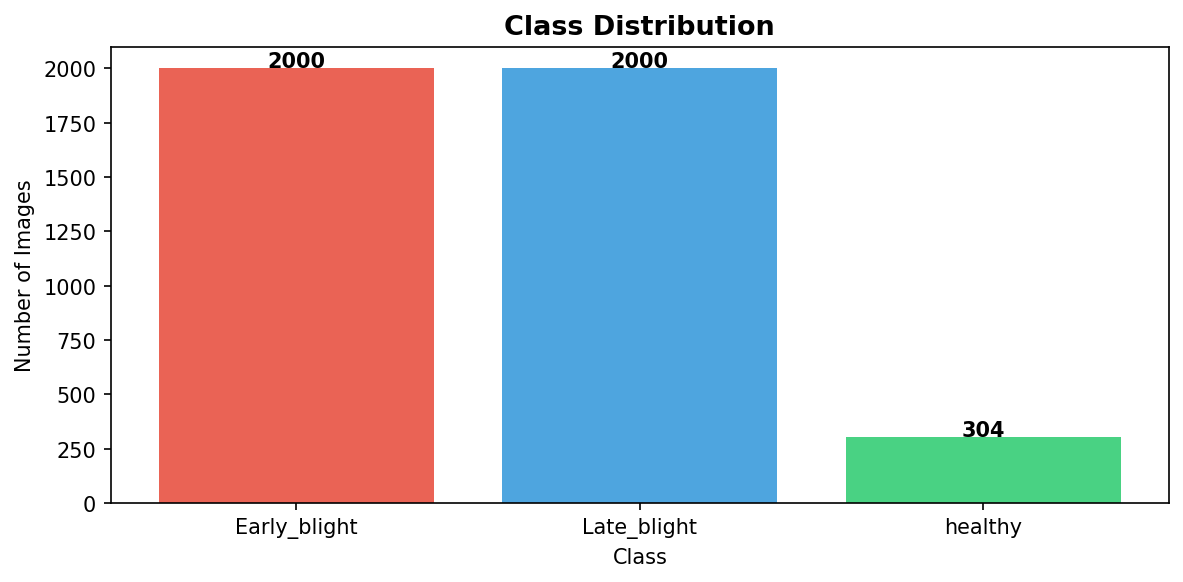

In [4]:
Image('legacy/figures/eda_distribution.png')

## 3. Effect of duplicated images (HOG + SVM, same code and parameters)

In [5]:
pd.read_csv('outputs/baseline/leakage_audit.csv')

                         scenario  accuracy  ...  n_test  shared_images
0     clean (2,152 unique images)  0.811146  ...     323              0
1  duplicated (4,304 = 2 x 2,152)  0.964396  ...     646            987

[2 rows x 7 columns]

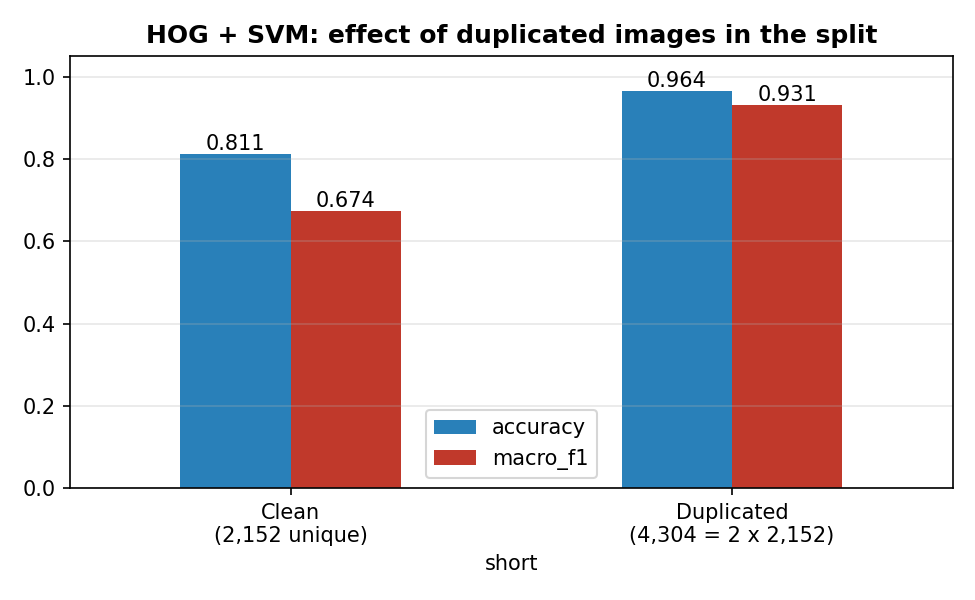

In [6]:
Image('reports/figures/leakage_impact.png')

## 4. Clean baseline results

In [7]:
pd.read_csv('outputs/baseline/model_metrics.csv')

       model  accuracy  macro_f1  ...  n_train  n_val  n_test
0  HOG + SVM  0.811146  0.673775  ...     1506    323     323

[1 rows x 9 columns]

In [8]:
pd.read_csv('outputs/baseline/per_class_metrics.csv')

       model         class  precision    recall        f1  support
0  HOG + SVM  Early_blight   0.843137  0.860000  0.851485      150
1  HOG + SVM   Late_blight   0.775758  0.853333  0.812698      150
2  HOG + SVM       healthy   1.000000  0.217391  0.357143       23

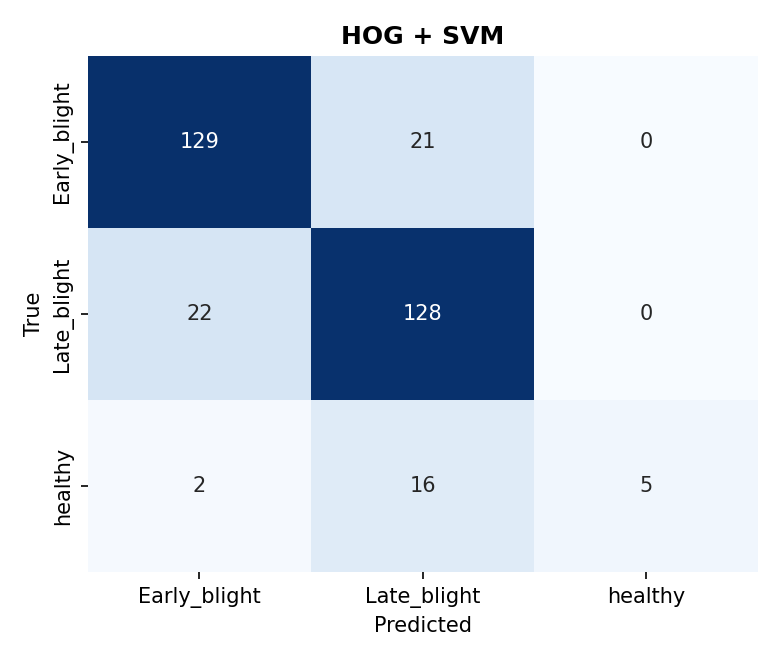

In [9]:
Image('reports/figures/confusion_matrices.png')

## 5. Robustness (HOG + SVM)

In [10]:
pd.read_csv('outputs/robustness/robustness_metrics.csv')

       model      corruption  severity  accuracy  macro_f1  weighted_f1
0  HOG + SVM            none      0.00  0.811146  0.673775     0.798272
1  HOG + SVM      brightness      0.70  0.814241  0.676356     0.801868
2  HOG + SVM      brightness      0.85  0.826625  0.665849     0.811153
3  HOG + SVM      brightness      1.15  0.814241  0.656946     0.798749
4  HOG + SVM      brightness      1.30  0.823529  0.663192     0.807452
5  HOG + SVM  gaussian_noise      0.01  0.811146  0.673997     0.798581
6  HOG + SVM  gaussian_noise      0.03  0.839009  0.742066     0.830902
7  HOG + SVM  gaussian_noise      0.05  0.761610  0.666186     0.750553
8  HOG + SVM            blur      1.00  0.773994  0.560955     0.748751
9  HOG + SVM            blur      2.00  0.650155  0.440038     0.613057

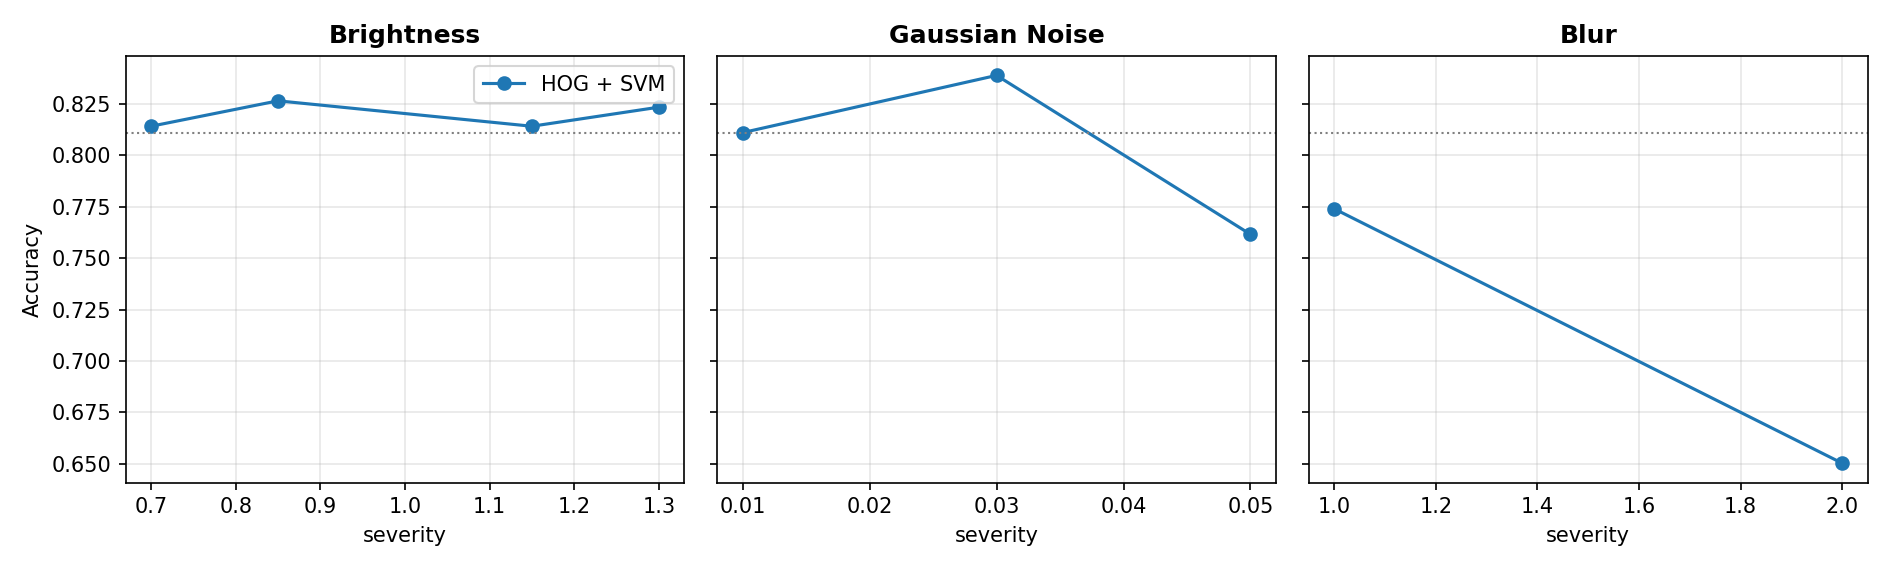

In [11]:
Image('reports/figures/robustness_curves.png')

## 6. HOG visualisation (from the original run)

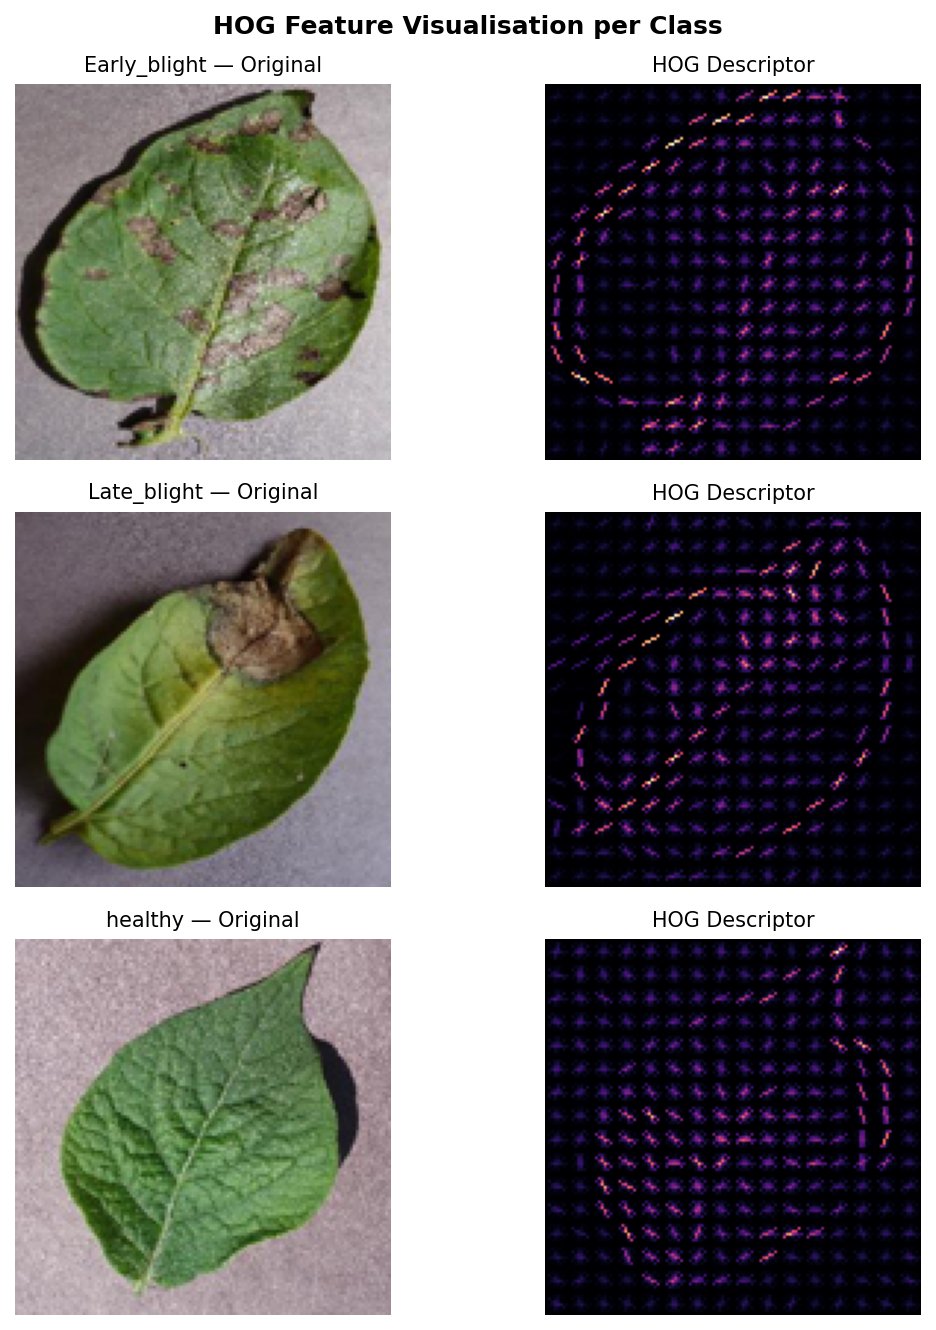

In [12]:
Image('reports/figures/hog_visualisation.png')

## Conclusions
- The public dataset has 2,152 unique images; the original run reports 4,304.
- On the clean split, HOG + SVM reaches ~81% accuracy with healthy recall 0.22.
- CNN results on the clean split are still to be produced (`scripts/run_experiments.py --models svm cnn`).